# Part 1

In [1]:
# All dependencies (pandas, matplotlib, statsmodels, scikit-learn) are pre-installed in .venv
# !pip install -q kagglehub pandas matplotlib statsmodels scikit-learn


In [2]:
# --- Original Code (not needed: dataset is already downloaded in data/) ---
# import kagglehub
# path = kagglehub.dataset_download("yazanalshuaibi/gas-furnace")

# Local dataset path (pre-downloaded in data/gas-furnace.csv)
path = "data"
print("Path to dataset files:", path)


Path to dataset files: data


This block downloads the Gas Furnace dataset from Kaggle and stores the location of the downloaded files in the variable

In [3]:
import pandas as pd
import os
df = pd.read_csv(os.path.join(path,"gas-furnace.csv"))

This block imports Pandas and loads gas-furnace.csv into a DataFrame called df

In [4]:
df = df[["CO2"]]
df.head()

,CO2
0,53.8
1,53.6
2,53.5
3,53.5
4,53.4


This block keeps only the CO2 column and displays the first five observations. The experiment is therefore univariate, because only one variable is used.

In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 296 entries, 0 to 295
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   CO2     296 non-null    float64
dtypes: float64(1)
memory usage: 2.4 KB


This block checks the structure of the dataset, including the number of observations, data type, and non-null values.

In [6]:
df.describe()


,CO2
count,296.000000
mean,53.509122
std,3.202121
min,45.600000
25%,51.200000
50%,53.500000
75%,56.000000
max,60.500000


This block calculates summary statistics such as the mean, standard deviation, minimum, maximum, and quartiles.

In [7]:
df.reset_index(drop=True, inplace=True)
df.head()


,CO2
0,53.8
1,53.6
2,53.5
3,53.5
4,53.4


This block resets the DataFrame index so the observations have a clean sequential numbering starting from zero.

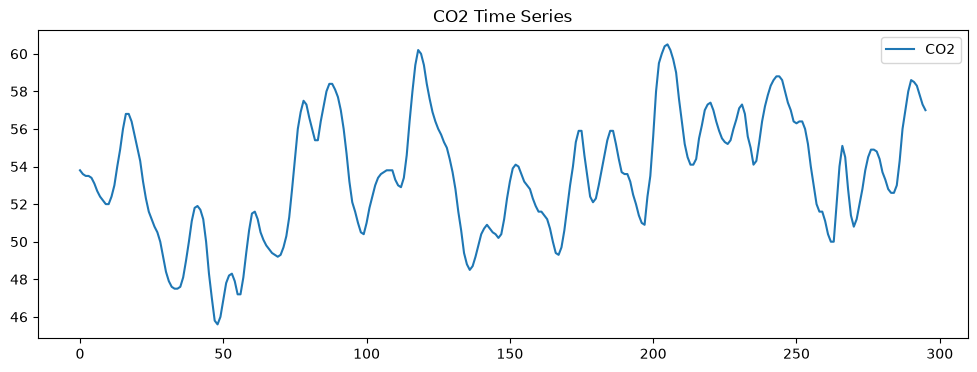

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))
plt.plot(df["CO2"], label="CO2")
plt.legend()
plt.title("CO2 Time Series")
plt.show()

This block visualizes how CO₂ changes across the sequence of observations.

<Figure size 640x480 with 0 Axes>

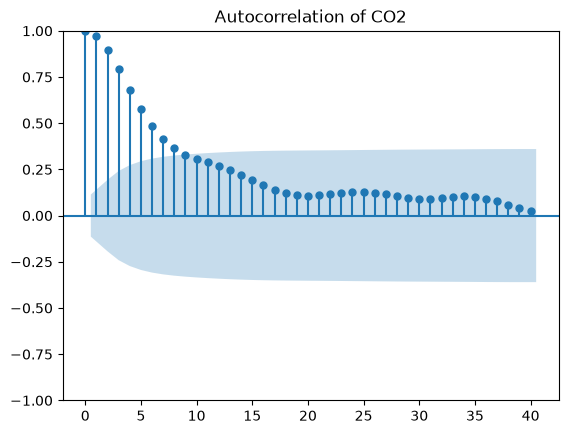

In [9]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure()
plot_acf(df["CO2"], lags=40)
plt.title("Autocorrelation of CO2")
plt.show()

This block calculates and plots the Autocorrelation Function, or ACF, for up to 40 lags. It measures how current CO₂ values are related to previous CO₂ values.

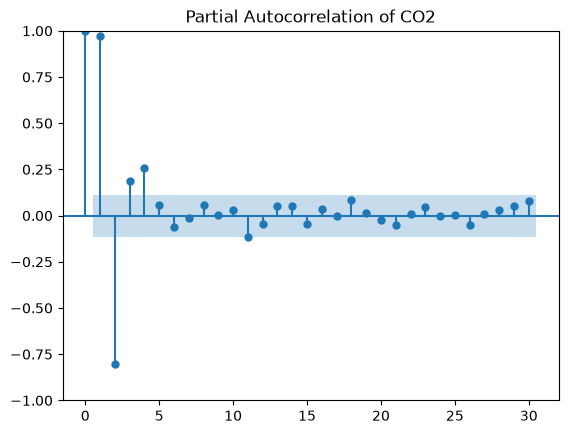

In [10]:
from statsmodels.graphics.tsaplots import plot_pacf

plot_pacf(df["CO2"], lags=30)
plt.title("Partial Autocorrelation of CO2")
plt.show()

This block plots the Partial Autocorrelation Function, or PACF, which examines the direct relationship between the current observation and individual previous lags.

In [11]:
def time_split(df, test_size=0.2):
    df.index = pd.date_range("2026-01-01", periods=len(df), freq="1s")
    n = len(df)
    split = int((1 - test_size) * n)
    return df.iloc[:split], df.iloc[split:]

This block defines a function that creates a synthetic one-second time index and splits the series chronologically into 80% training and 20% testing data.

In [12]:
train, test = time_split(df)

This block actually creates the training and testing datasets.

In [13]:
train

,CO2
2026-01-01 00:00:00,53.8
2026-01-01 00:00:01,53.6
2026-01-01 00:00:02,53.5
2026-01-01 00:00:03,53.5
2026-01-01 00:00:04,53.4
...,...
2026-01-01 00:03:51,57.3
2026-01-01 00:03:52,56.8
2026-01-01 00:03:53,55.6
2026-01-01 00:03:54,55.0


This simply displays the training portion so we can verify that the split worked correctly.

In [14]:
from statsmodels.tsa.arima.model import ARIMA

arima = ARIMA(
    train["CO2"],
    order=(3, 0, 1),
    trend="c",
    enforce_stationarity=False,
    enforce_invertibility=False
)
arima_fit = arima.fit()

fit_ext = arima_fit.apply(df["CO2"])

pred = fit_ext.get_prediction(start=int(0.8 * len(df)), end=len(df)-1, dynamic=False)

yhat_arima = pred.predicted_mean.to_numpy()

c:\Users\Chanreach\Documents\feco303-ml-pipeline-api\deployment_template\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


This block creates and trains the ARIMA(3,0,1) model using the training CO₂ values.

In [15]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(test, yhat_arima)
print(f"ARIMA(3,0,1) MAE: {mae:.4f}")

ARIMA(3,0,1) MAE: 0.3018


This block applies the fitted ARIMA model and generates predictions beginning at the 20% test portion of the dataset

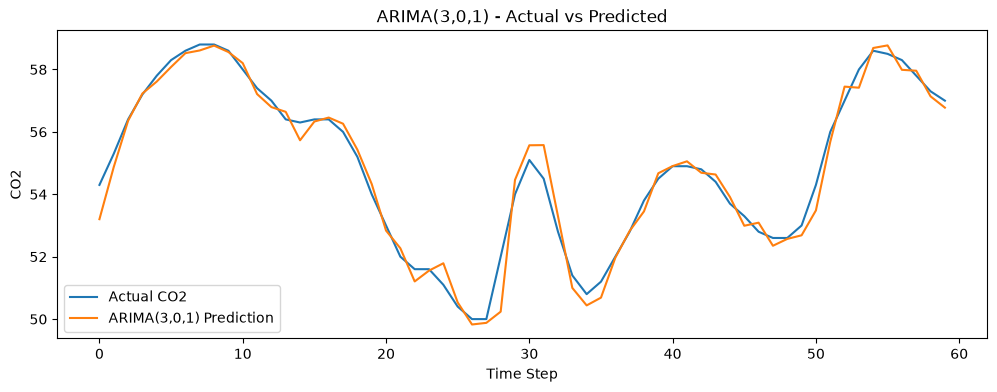

In [16]:
plt.figure(figsize=(12, 4))
plt.plot(range(len(test)), test, label="Actual CO2")
plt.plot(range(len(yhat_arima)), yhat_arima, label="ARIMA(3,0,1) Prediction")
plt.legend()
plt.title("ARIMA(3,0,1) - Actual vs Predicted")
plt.xlabel("Time Step")
plt.ylabel("CO2")
plt.show()

This block evaluates the predictions using Mean Absolute Error, or MAE.